In [1]:

import zipfile
import os

zip_path = "/content/store item dataset.zip"
extract_path = "/content/retail_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)


Extraction completed!
retail_sales.csv


In [2]:

import pandas as pd

file_path = "/content/retail_dataset/retail_sales.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Number of rows: 4565000
Number of columns: 8

Column names:
['date', 'store_id', 'item_id', 'sales', 'price', 'promo', 'weekday', 'month']

First 5 rows:


,date,store_id,item_id,sales,price,promo,weekday,month
0,2019-01-01,store_1,item_1,41,21.30,0,1,1
1,2019-01-02,store_1,item_1,53,21.30,0,2,1
2,2019-01-03,store_1,item_1,39,21.30,0,3,1
3,2019-01-04,store_1,item_1,35,21.30,0,4,1
4,2019-01-05,store_1,item_1,51,17.04,1,5,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4565000 entries, 0 to 4564999
Data columns (total 8 columns):
 #   Column    Dtype  
---  ------    -----  
 0   date      object 
 1   store_id  object 
 2   item_id   object 
 3   sales     int64  
 4   price     float64
 5   promo     int64  
 6   weekday   int64  
 7   month     int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 278.6+ MB


In [3]:


df["date"] = pd.to_datetime(df["date"])

print("1. Dataset shape:", df.shape)

print("\n2. Date range:")
print("Start date:", df["date"].min().date())
print("End date:", df["date"].max().date())

print("\n3. Number of stores:", df["store_id"].nunique())
print("4. Number of products:", df["item_id"].nunique())

print("\n5. Missing values in each column:")
print(df.isnull().sum())

print("\n6. Duplicate rows:", df.duplicated().sum())

print("\n7. Sales statistics:")
print(df["sales"].describe())

print("\n8. Invalid values:")
print("Negative sales:", (df["sales"] < 0).sum())
print("Zero prices:", (df["price"] == 0).sum())
print("Negative prices:", (df["price"] < 0).sum())


1. Dataset shape: (4565000, 8)

2. Date range:
Start date: 2019-01-01
End date: 2023-12-31

3. Number of stores: 50
4. Number of products: 50

5. Missing values in each column:
date        0
store_id    0
item_id     0
sales       0
price       0
promo       0
weekday     0
month       0
dtype: int64

6. Duplicate rows: 0

7. Sales statistics:
count    4.565000e+06
mean     2.926466e+01
std      1.500996e+01
min      0.000000e+00
25%      1.800000e+01
50%      2.700000e+01
75%      3.800000e+01
max      1.390000e+02
Name: sales, dtype: float64

8. Invalid values:
Negative sales: 0
Zero prices: 0
Negative prices: 0


In [4]:


full_data = df.copy()


full_data = full_data.sort_values(
    ["store_id", "item_id", "date"]
).reset_index(drop=True)


full_data["series_id"] = (
    full_data["store_id"] + "_" + full_data["item_id"]
)

print("Full dataset shape:", full_data.shape)
print("Unique store-product combinations:",
      full_data["series_id"].nunique())
print("Unique stores:", full_data["store_id"].nunique())
print("Unique products:", full_data["item_id"].nunique())

display(full_data.head())


Full dataset shape: (4565000, 9)
Unique store-product combinations: 2500
Unique stores: 50
Unique products: 50


,date,store_id,item_id,sales,price,promo,weekday,month,series_id
0,2019-01-01,store_1,item_1,41,21.30,0,1,1,store_1_item_1
1,2019-01-02,store_1,item_1,53,21.30,0,2,1,store_1_item_1
2,2019-01-03,store_1,item_1,39,21.30,0,3,1,store_1_item_1
3,2019-01-04,store_1,item_1,35,21.30,0,4,1,store_1_item_1
4,2019-01-05,store_1,item_1,51,17.04,1,5,1,store_1_item_1


In [5]:


print("TOTAL SALES SUMMARY")
print("Total units sold:", full_data["sales"].sum())
print("Average units sold per record:", round(full_data["sales"].mean(), 2))
print("Highest units sold in one record:", full_data["sales"].max())


store_sales = (
    full_data.groupby("store_id")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTOP 10 STORES BY UNITS SOLD")
display(store_sales.head(10).reset_index(name="total_units_sold"))


product_sales = (
    full_data.groupby("item_id")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTOP 10 PRODUCTS BY UNITS SOLD")
display(product_sales.head(10).reset_index(name="total_units_sold"))


promo_sales = full_data.groupby("promo").agg(
    total_units=("sales", "sum"),
    average_units_per_record=("sales", "mean"),
    record_count=("sales", "size")
)

print("\nSALES BY PROMOTION STATUS (0 = No, 1 = Yes)")
display(promo_sales.round(2))


TOTAL SALES SUMMARY
Total units sold: 133593174
Average units sold per record: 29.26
Highest units sold in one record: 139

TOP 10 STORES BY UNITS SOLD


,store_id,total_units_sold
0,store_12,3243496
1,store_35,3240494
2,store_2,3221215
3,store_34,3218908
4,store_44,3179667
5,store_8,3132417
6,store_13,3094882
7,store_36,3069321
8,store_26,3041146
9,store_3,2983937



TOP 10 PRODUCTS BY UNITS SOLD


,item_id,total_units_sold
0,item_20,4261507
1,item_1,4207065
2,item_3,4108554
3,item_6,4051413
4,item_4,3964580
5,item_39,3938555
6,item_31,3861901
7,item_13,3752355
8,item_24,3710934
9,item_18,3665037



SALES BY PROMOTION STATUS (0 = No, 1 = Yes)


,total_units,average_units_per_record,record_count
promo,,,
0,114482812,27.86,4108506
1,19110362,41.86,456494


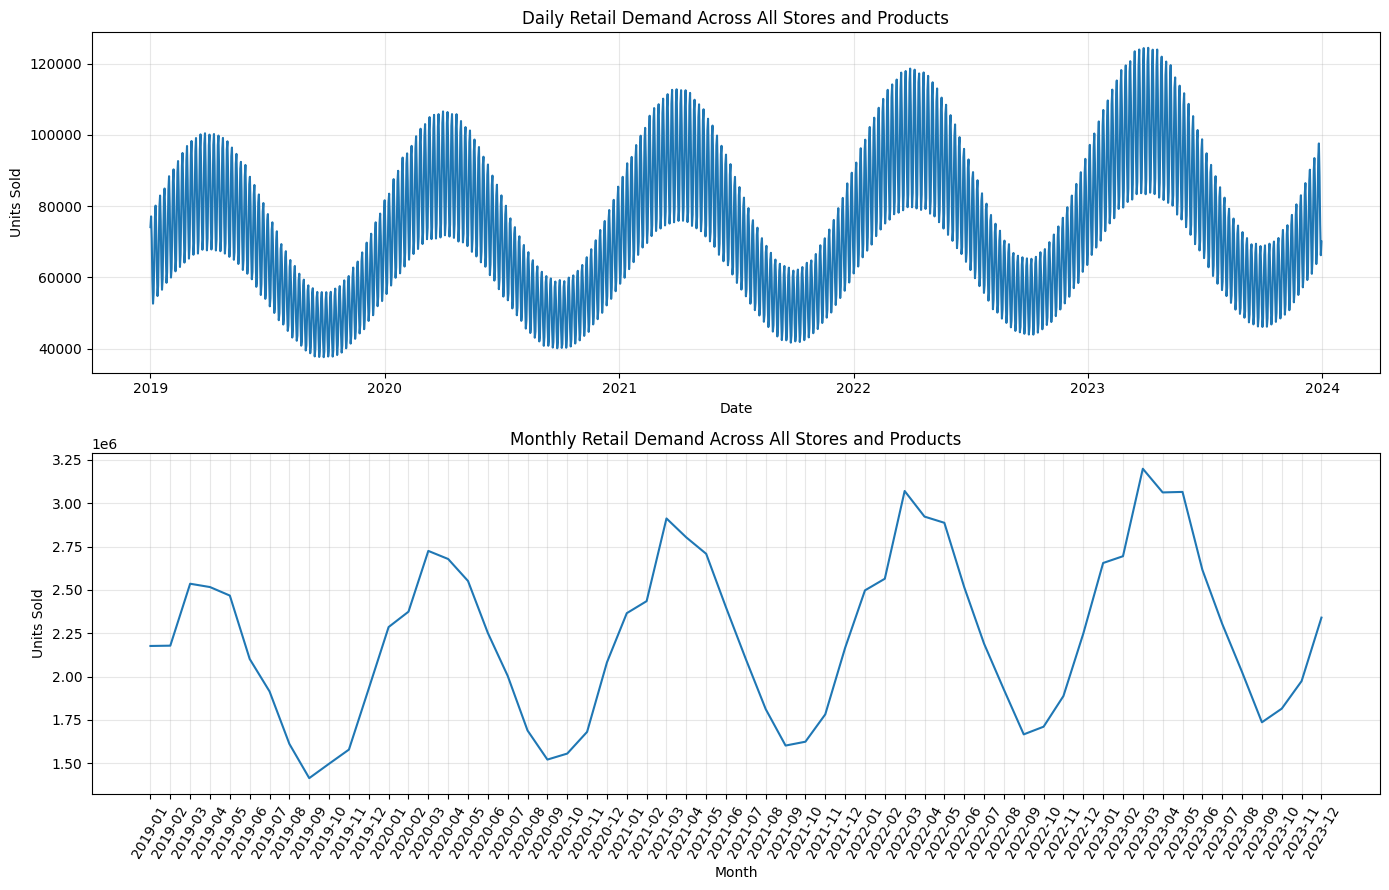

In [6]:

import matplotlib.pyplot as plt


daily_sales = (
    full_data.groupby("date", as_index=False)["sales"]
    .sum()
)


monthly_sales = (
    full_data.groupby(full_data["date"].dt.to_period("M"))["sales"]
    .sum()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))


axes[0].plot(daily_sales["date"], daily_sales["sales"])
axes[0].set_title("Daily Retail Demand Across All Stores and Products")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Units Sold")
axes[0].grid(True, alpha=0.3)


axes[1].plot(monthly_sales.index.astype(str), monthly_sales.values)
axes[1].set_title("Monthly Retail Demand Across All Stores and Products")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Units Sold")
axes[1].tick_params(axis="x", rotation=60)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [7]:



import pandas as pd
import numpy as np


ml_data = full_data.copy()


ml_data["day_of_week"] = ml_data["date"].dt.dayofweek
ml_data["day_of_month"] = ml_data["date"].dt.day
ml_data["year"] = ml_data["date"].dt.year


ml_data = ml_data.sort_values(
    ["series_id", "date"]
).reset_index(drop=True)

grouped_sales = ml_data.groupby("series_id")["sales"]


ml_data["lag_1"] = grouped_sales.shift(1)
ml_data["lag_7"] = grouped_sales.shift(7)
ml_data["lag_14"] = grouped_sales.shift(14)


ml_data["rolling_mean_7"] = (
    ml_data.groupby("series_id")["sales"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

ml_data["rolling_mean_28"] = (
    ml_data.groupby("series_id")["sales"]
    .transform(lambda s: s.shift(1).rolling(28).mean())
)

print("Feature engineering completed!")
print("Shape:", ml_data.shape)

print("\nNew columns:")
print([
    "day_of_week", "day_of_month", "year",
    "lag_1", "lag_7", "lag_14",
    "rolling_mean_7", "rolling_mean_28"
])

display(ml_data.head(35))


Feature engineering completed!
Shape: (4565000, 17)

New columns:
['day_of_week', 'day_of_month', 'year', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_28']


,date,store_id,item_id,sales,price,promo,weekday,month,series_id,day_of_week,day_of_month,year,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_28
0,2019-01-01,store_10,item_1,51,10.79,0,1,1,store_10_item_1,1,1,2019,NaN,NaN,NaN,NaN,NaN
1,2019-01-02,store_10,item_1,52,10.79,0,2,1,store_10_item_1,2,2,2019,51.0,NaN,NaN,NaN,NaN
2,2019-01-03,store_10,item_1,51,10.79,0,3,1,store_10_item_1,3,3,2019,52.0,NaN,NaN,NaN,NaN
3,2019-01-04,store_10,item_1,41,10.79,0,4,1,store_10_item_1,4,4,2019,51.0,NaN,NaN,NaN,NaN
4,2019-01-05,store_10,item_1,33,10.79,0,5,1,store_10_item_1,5,5,2019,41.0,NaN,NaN,NaN,NaN
5,2019-01-06,store_10,item_1,59,8.63,1,6,1,store_10_item_1,6,6,2019,33.0,NaN,NaN,NaN,NaN
6,2019-01-07,store_10,item_1,43,10.79,0,0,1,store_10_item_1,0,7,2019,59.0,NaN,NaN,NaN,NaN
7,2019-01-08,store_10,item_1,81,8.63,1,1,1,store_10_item_1,1,8,2019,43.0,51.0,NaN,47.142857,NaN
8,2019-01-09,store_10,item_1,55,10.79,0,2,1,store_10_item_1,2,9,2019,81.0,52.0,NaN,51.428571,NaN
9,2019-01-10,store_10,item_1,47,10.79,0,3,1,store_10_item_1,3,10,2019,55.0,51.0,NaN,51.857143,NaN


In [8]:


model_data = ml_data.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_14",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
).copy()


train = model_data[model_data["date"] < "2023-01-01"].copy()

validation = model_data[
    (model_data["date"] >= "2023-01-01") &
    (model_data["date"] < "2023-07-01")
].copy()

test = model_data[
    (model_data["date"] >= "2023-07-01") &
    (model_data["date"] <= "2023-12-31")
].copy()

print("Training period:", train["date"].min().date(), "to", train["date"].max().date())
print("Validation period:", validation["date"].min().date(), "to", validation["date"].max().date())
print("Testing period:", test["date"].min().date(), "to", test["date"].max().date())

print("\nTraining rows:", len(train))
print("Validation rows:", len(validation))
print("Testing rows:", len(test))

print("\nMissing values in training features:")
display(train.isnull().sum())


Training period: 2019-01-29 to 2022-12-31
Validation period: 2023-01-01 to 2023-06-30
Testing period: 2023-07-01 to 2023-12-31

Training rows: 3582500
Validation rows: 452500
Testing rows: 460000

Missing values in training features:


,0
date,0
store_id,0
item_id,0
sales,0
price,0
promo,0
weekday,0
month,0
series_id,0
day_of_week,0


In [9]:

%pip install -q xgboost


In [10]:


import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


features = [
    "store_id",
    "item_id",
    "price",
    "promo",
    "weekday",
    "month",
    "day_of_week",
    "day_of_month",
    "year",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_28"
]


target = "sales"


X_train = pd.get_dummies(train[features], columns=["store_id", "item_id"])
X_val = pd.get_dummies(validation[features], columns=["store_id", "item_id"])
X_test = pd.get_dummies(test[features], columns=["store_id", "item_id"])


X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


y_train = train[target]
y_val = validation[target]
y_test = test[target]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)
print("Data preparation completed successfully!")


Training features: (3582500, 112)
Validation features: (452500, 112)
Testing features: (460000, 112)
Data preparation completed successfully!


In [11]:


model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=2,
    random_state=42
)


model.fit(X_train, y_train, verbose=False)

print("XGBoost model training completed successfully!")


XGBoost model training completed successfully!


In [2]:

print("Model exists:", "model" in globals())
print("Training data exists:", "X_train" in globals())
print("Validation data exists:", "X_val" in globals())


Model exists: False
Training data exists: False
Validation data exists: False


In [3]:

import os

file_path = "/content/retail_dataset/retail_sales.csv"

if os.path.exists(file_path):
    print("Dataset file found!")
    print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")
else:
    print("Dataset file not found. We need to upload the ZIP file again.")


Dataset file not found. We need to upload the ZIP file again.


In [4]:

import os
import zipfile

zip_path = "/content/store item dataset.zip"
extract_path = "/content/retail_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))


ZIP file extracted successfully!
/content/retail_dataset/retail_sales.csv


In [6]:

for name in ["ml_data", "train", "X_train", "y_train", "X_val", "y_val", "model"]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


ml_data: Missing
train: Missing
X_train: Missing
y_train: Missing
X_val: Missing
y_val: Missing
model: Missing


In [7]:

import os
import pandas as pd
import numpy as np

file_path = "/content/retail_dataset/retail_sales.csv"

if not os.path.exists(file_path):
    print("Dataset file is missing. Please upload and extract the ZIP again.")
else:
    df = pd.read_csv(file_path, parse_dates=["date"])

    full_data = df.sort_values(
        ["store_id", "item_id", "date"]
    ).reset_index(drop=True)

    full_data["series_id"] = (
        full_data["store_id"].astype(str)
        + "_"
        + full_data["item_id"].astype(str)
    )

    print("Dataset loaded successfully!")
    print("Shape:", full_data.shape)
    print("Date range:", full_data["date"].min(), "to", full_data["date"].max())


Dataset loaded successfully!
Shape: (4565000, 9)
Date range: 2019-01-01 00:00:00 to 2023-12-31 00:00:00


In [8]:

ml_data = full_data.copy()

ml_data["day_of_week"] = ml_data["date"].dt.dayofweek
ml_data["day_of_month"] = ml_data["date"].dt.day
ml_data["year"] = ml_data["date"].dt.year

ml_data = ml_data.sort_values(
    ["series_id", "date"]
).reset_index(drop=True)

grouped_sales = ml_data.groupby("series_id")["sales"]

ml_data["lag_1"] = grouped_sales.shift(1)
ml_data["lag_7"] = grouped_sales.shift(7)
ml_data["lag_14"] = grouped_sales.shift(14)

ml_data["rolling_mean_7"] = (
    ml_data.groupby("series_id")["sales"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

ml_data["rolling_mean_28"] = (
    ml_data.groupby("series_id")["sales"]
    .transform(lambda s: s.shift(1).rolling(28).mean())
)

print("Features recreated:", ml_data.shape)


Features recreated: (4565000, 17)


In [9]:

model_data = ml_data.dropna(
    subset=[
        "lag_1", "lag_7", "lag_14",
        "rolling_mean_7", "rolling_mean_28"
    ]
).copy()

train = model_data[model_data["date"] < "2023-01-01"].copy()

validation = model_data[
    (model_data["date"] >= "2023-01-01") &
    (model_data["date"] < "2023-07-01")
].copy()

test = model_data[
    (model_data["date"] >= "2023-07-01") &
    (model_data["date"] < "2024-01-01")
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Testing rows:", len(test))


Training rows: 3582500
Validation rows: 452500
Testing rows: 460000


In [10]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


features = [
    "store_id", "item_id", "price", "promo",
    "weekday", "month", "day_of_week", "day_of_month",
    "year", "lag_1", "lag_7", "lag_14",
    "rolling_mean_7", "rolling_mean_28"
]


X_train = pd.get_dummies(
    train[features], columns=["store_id", "item_id"]
)
X_val = pd.get_dummies(
    validation[features], columns=["store_id", "item_id"]
)
X_test = pd.get_dummies(
    test[features], columns=["store_id", "item_id"]
)


X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


y_train = train["sales"]
y_val = validation["sales"]
y_test = test["sales"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)
print("Data preparation completed!")


Training features: (3582500, 112)
Validation features: (452500, 112)
Testing features: (460000, 112)
Data preparation completed!


In [11]:

from xgboost import XGBRegressor

# Create the model
model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=2,
    random_state=42
)

# Train using historical sales data
model.fit(X_train, y_train, verbose=False)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


In [12]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error


val_predictions = model.predict(X_val)


val_predictions = np.maximum(val_predictions, 0)


mae = mean_absolute_error(y_val, val_predictions)

rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

wape = (
    np.sum(np.abs(y_val.to_numpy() - val_predictions))
    / np.sum(y_val.to_numpy())
) * 100


print("XGBoost Validation Results")
print("--------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")


XGBoost Validation Results
--------------------------
MAE:  2.59
RMSE: 3.25
WAPE: 6.77%


In [13]:


baseline_predictions = validation["lag_7"].to_numpy()

actual_sales = y_val.to_numpy()


baseline_mae = mean_absolute_error(
    actual_sales, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_sales, baseline_predictions)
)

baseline_wape = (
    np.abs(actual_sales - baseline_predictions).sum()
    / actual_sales.sum()
) * 100


comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "XGBoost"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(actual_sales, val_predictions)
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(actual_sales, val_predictions))
    ],
    "WAPE (%)": [
        baseline_wape,
        np.abs(actual_sales - val_predictions).sum()
        / actual_sales.sum() * 100
    ]
})

print(comparison.round(2).to_string(index=False))


         Model  MAE  RMSE  WAPE (%)
Seasonal Naive 6.09  9.43     15.95
       XGBoost 2.59  3.25      6.77


In [14]:


test_predictions = model.predict(X_test)


test_predictions = np.maximum(test_predictions, 0)


test_mae = mean_absolute_error(y_test, test_predictions)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_wape = (
    np.abs(y_test.to_numpy() - test_predictions).sum()
    / y_test.to_numpy().sum()
) * 100

print("Final XGBoost Test Results")
print("--------------------------")
print(f"MAE:  {test_mae:.2f}")
print(f"RMSE: {test_rmse:.2f}")
print(f"WAPE: {test_wape:.2f}%")


Final XGBoost Test Results
--------------------------
MAE:  2.52
RMSE: 3.16
WAPE: 9.52%


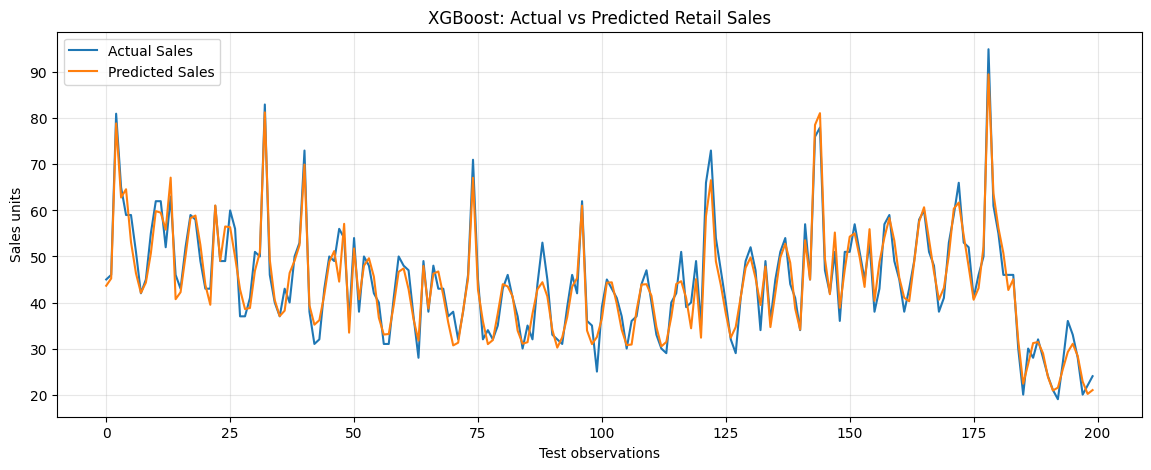

In [15]:

import matplotlib.pyplot as plt


comparison = pd.DataFrame({
    "Actual Sales": y_test.to_numpy(),
    "Predicted Sales": test_predictions
})


sample = comparison.head(200)

plt.figure(figsize=(14, 5))
plt.plot(
    sample["Actual Sales"].to_numpy(),
    label="Actual Sales"
)
plt.plot(
    sample["Predicted Sales"].to_numpy(),
    label="Predicted Sales"
)

plt.title("XGBoost: Actual vs Predicted Retail Sales")
plt.xlabel("Test observations")
plt.ylabel("Sales units")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Top 15 Important Features:
        Feature  Importance
          promo    0.533613
          lag_7    0.197493
         lag_14    0.109266
rolling_mean_28    0.071958
 rolling_mean_7    0.044550
        weekday    0.014967
    day_of_week    0.008729
          month    0.004381
          lag_1    0.004239
item_id_item_23    0.000303
item_id_item_20    0.000292
 item_id_item_1    0.000289
item_id_item_49    0.000270
 item_id_item_3    0.000242
 item_id_item_9    0.000235


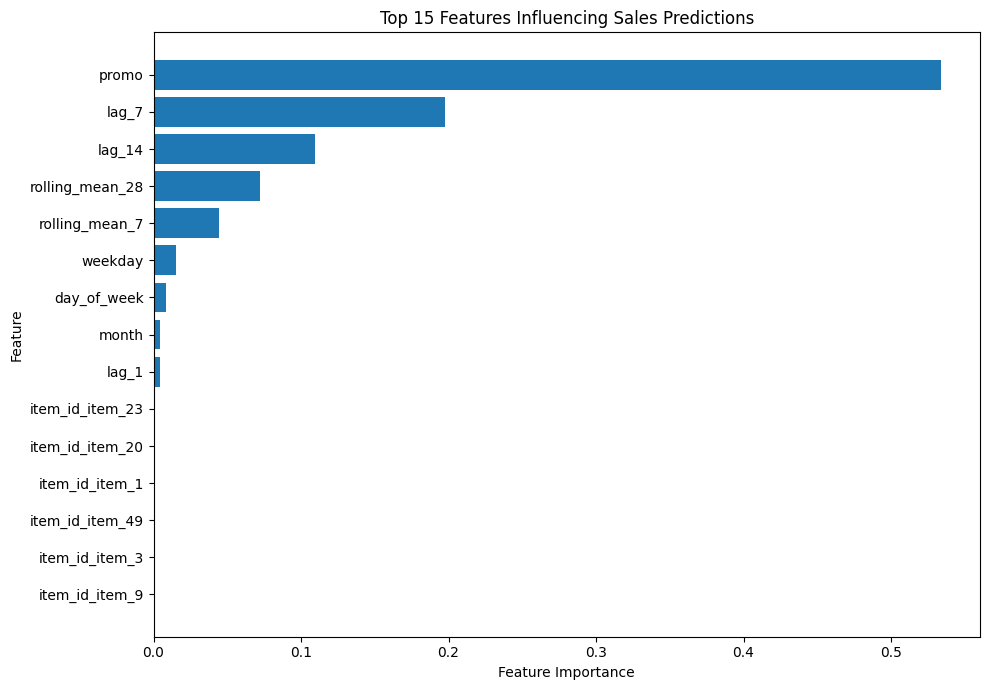

In [16]:

import pandas as pd
import matplotlib.pyplot as plt


importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})


importance = importance.sort_values(
    by="Importance", ascending=False
)


print("Top 15 Important Features:")
print(importance.head(15).to_string(index=False))


top_features = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features Influencing Sales Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [17]:


inventory_plan = test[
    ["store_id", "item_id", "date", "sales", "price", "promo"]
].copy()

inventory_plan["predicted_sales"] = test_predictions


inventory_summary = (
    inventory_plan.groupby(["store_id", "item_id"])
    .agg(
        actual_sales=("sales", "sum"),
        predicted_sales=("predicted_sales", "sum"),
        average_daily_forecast=("predicted_sales", "mean"),
        days=("date", "nunique")
    )
    .reset_index()
)


inventory_summary["suggested_stock_7_days"] = np.ceil(
    inventory_summary["average_daily_forecast"] * 7
).astype(int)


inventory_summary = inventory_summary.sort_values(
    "predicted_sales", ascending=False
)

print("Inventory Planning Summary")
print(inventory_summary.head(20).to_string(index=False))


Inventory Planning Summary
store_id item_id  actual_sales  predicted_sales  average_daily_forecast  days  suggested_stock_7_days
store_35  item_1          9496      9494.543945               51.600780   184                     362
 store_2 item_20          9492      9383.323242               50.996323   184                     357
store_34 item_20          9427      9335.199219               50.734779   184                     356
store_35 item_20          9401      9305.683594               50.574368   184                     355
store_12 item_20          9376      9241.297852               50.224445   184                     352
store_34  item_3          9240      9187.364258               49.931328   184                     350
store_44 item_20          9308      9178.176758               49.881397   184                     350
store_13 item_20          9233      9166.208008               49.816349   184                     349
store_12  item_1          9268      9155.178711        

In [18]:

# Inventory planning assumptions
lead_time_days = 3
safety_stock_percentage = 0.20

# Expected demand during supplier delivery time
inventory_summary["lead_time_demand"] = (
    inventory_summary["average_daily_forecast"]
    * lead_time_days
)

# Extra stock to protect against unexpected demand
inventory_summary["safety_stock"] = np.ceil(
    inventory_summary["lead_time_demand"]
    * safety_stock_percentage
).astype(int)

# Reorder point = lead-time demand + safety stock
inventory_summary["reorder_point"] = np.ceil(
    inventory_summary["lead_time_demand"]
).astype(int) + inventory_summary["safety_stock"]

# Display the results
print("Inventory Reorder Planning")
print(
    inventory_summary[
        [
            "store_id",
            "item_id",
            "average_daily_forecast",
            "lead_time_demand",
            "safety_stock",
            "reorder_point"
        ]
    ].head(20).round(2).to_string(index=False)
)


Inventory Reorder Planning
store_id item_id  average_daily_forecast  lead_time_demand  safety_stock  reorder_point
store_35  item_1               51.599998        154.800003            31            186
 store_2 item_20               51.000000        152.990005            31            184
store_34 item_20               50.730000        152.199997            31            184
store_35 item_20               50.570000        151.720001            31            183
store_12 item_20               50.220001        150.669998            31            182
store_34  item_3               49.930000        149.789993            30            180
store_44 item_20               49.880001        149.639999            30            180
store_13 item_20               49.820000        149.449997            30            180
store_12  item_1               49.759998        149.270004            30            180
 store_2  item_3               49.540001        148.610001            30            179
store

In [19]:


inventory_summary["current_stock"] = 100


inventory_summary["reorder_quantity"] = np.maximum(
    inventory_summary["suggested_stock_7_days"]
    - inventory_summary["current_stock"],
    0
)


inventory_summary["reorder_status"] = np.where(
    inventory_summary["current_stock"]
    <= inventory_summary["reorder_point"],
    "Reorder",
    "Stock sufficient"
)


print("Final Inventory Recommendations")
print(
    inventory_summary[
        [
            "store_id",
            "item_id",
            "current_stock",
            "reorder_point",
            "suggested_stock_7_days",
            "reorder_quantity",
            "reorder_status"
        ]
    ].head(20).to_string(index=False)
)


Final Inventory Recommendations
store_id item_id  current_stock  reorder_point  suggested_stock_7_days  reorder_quantity reorder_status
store_35  item_1            100            186                     362               262        Reorder
 store_2 item_20            100            184                     357               257        Reorder
store_34 item_20            100            184                     356               256        Reorder
store_35 item_20            100            183                     355               255        Reorder
store_12 item_20            100            182                     352               252        Reorder
store_34  item_3            100            180                     350               250        Reorder
store_44 item_20            100            180                     350               250        Reorder
store_13 item_20            100            180                     349               249        Reorder
store_12  item_1            100 

In [20]:

forecast_results = test[
    ["date", "store_id", "item_id", "sales"]
].copy()

forecast_results["predicted_sales"] = test_predictions

forecast_results.to_csv(
    "/content/xgboost_test_predictions.csv",
    index=False
)


inventory_summary.to_csv(
    "/content/inventory_recommendations.csv",
    index=False
)

print("Files saved successfully!")
print("1. xgboost_test_predictions.csv")
print("2. inventory_recommendations.csv")

print("\nForecast results:")
display(forecast_results.head())

print("\nInventory recommendations:")
display(inventory_summary.head())

Files saved successfully!
1. xgboost_test_predictions.csv
2. inventory_recommendations.csv

Forecast results:


,date,store_id,item_id,sales,predicted_sales
1642,2023-07-01,store_10,item_1,45,43.642723
1643,2023-07-02,store_10,item_1,46,45.218597
1644,2023-07-03,store_10,item_1,81,78.886040
1645,2023-07-04,store_10,item_1,65,62.795116
1646,2023-07-05,store_10,item_1,59,64.594589



Inventory recommendations:


,store_id,item_id,actual_sales,predicted_sales,average_daily_forecast,days,suggested_stock_7_days,lead_time_demand,safety_stock,reorder_point,current_stock,reorder_quantity,reorder_status
1400,store_35,item_1,9496,9494.543945,51.600780,184,362,154.802338,31,186,100,262,Reorder
562,store_2,item_20,9492,9383.323242,50.996323,184,357,152.988968,31,184,100,257,Reorder
1362,store_34,item_20,9427,9335.199219,50.734779,184,356,152.204346,31,184,100,256,Reorder
1412,store_35,item_20,9401,9305.683594,50.574368,184,355,151.723099,31,183,100,255,Reorder
162,store_12,item_20,9376,9241.297852,50.224445,184,352,150.673340,31,182,100,252,Reorder


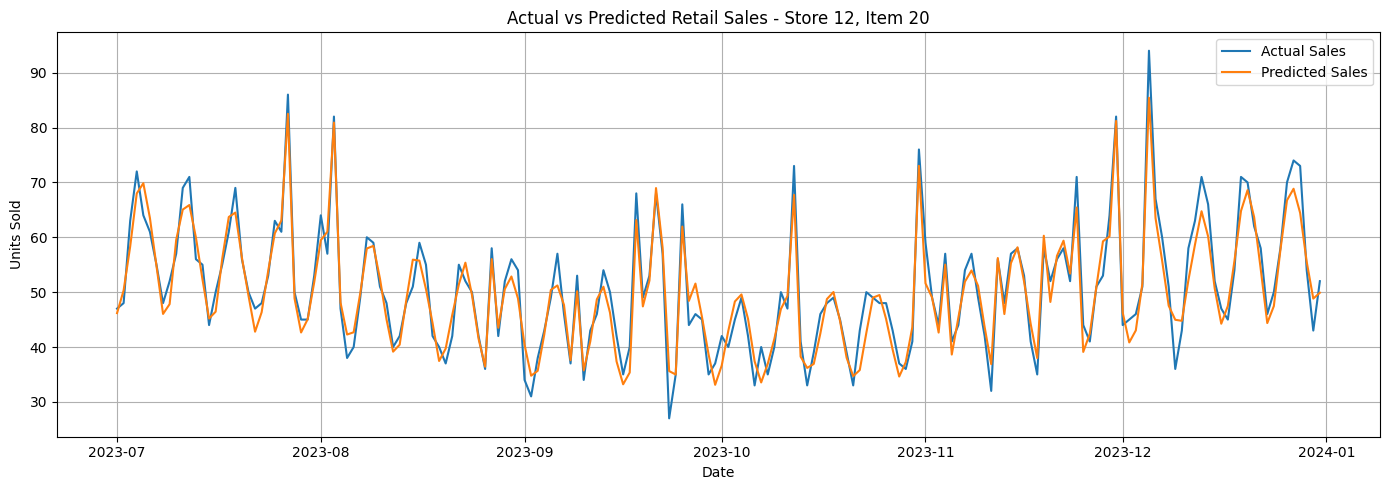

In [21]:
import matplotlib.pyplot as plt


sample = forecast_results[
    (forecast_results["store_id"] == "store_12") &
    (forecast_results["item_id"] == "item_20")
].sort_values("date")

plt.figure(figsize=(14, 5))

plt.plot(
    sample["date"],
    sample["sales"],
    label="Actual Sales"
)

plt.plot(
    sample["date"],
    sample["predicted_sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Retail Sales - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Total daily records: 1826
Missing values: 0


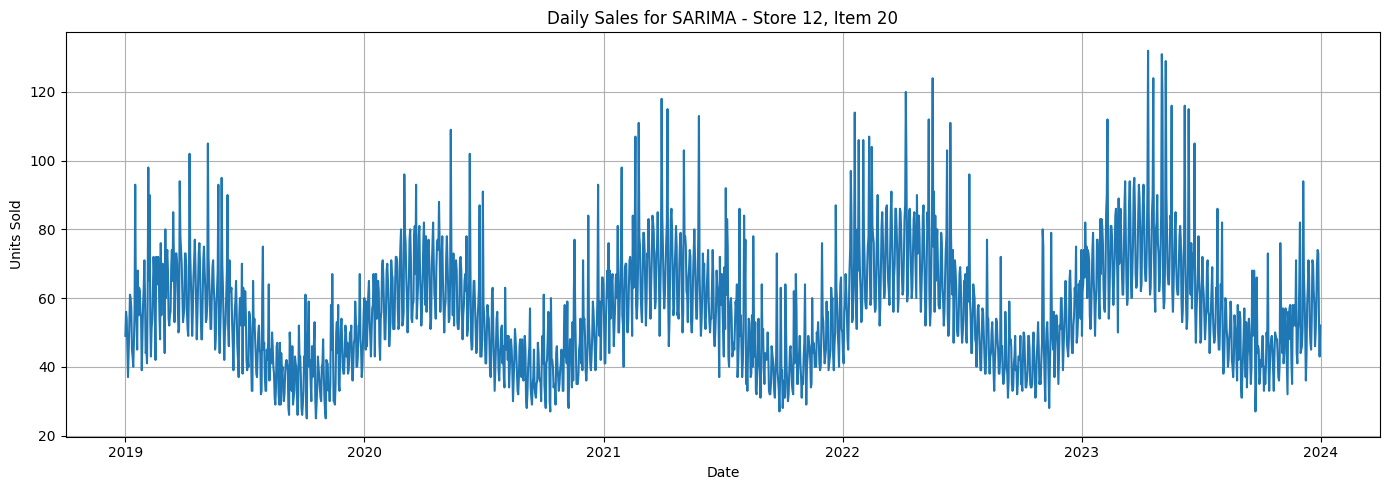

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


sarima_data = df[
    (df["store_id"] == "store_12") &
    (df["item_id"] == "item_20")
].copy()

sarima_data["date"] = pd.to_datetime(sarima_data["date"])
sarima_data = sarima_data.sort_values("date")


sales_series = (
    sarima_data.set_index("date")["sales"]
    .asfreq("D")
)

print("Total daily records:", len(sales_series))
print("Missing values:", sales_series.isna().sum())


plt.figure(figsize=(14, 5))
plt.plot(sales_series)
plt.title("Daily Sales for SARIMA - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:

train_sarima = sales_series[
    sales_series.index < "2023-01-01"
]

test_sarima = sales_series[
    sales_series.index >= "2023-01-01"
]

print("Training data:", len(train_sarima))
print("Testing data:", len(test_sarima))

print("\nTraining period:")
print(train_sarima.index.min(), "to", train_sarima.index.max())

print("\nTesting period:")
print(test_sarima.index.min(), "to", test_sarima.index.max())

Training data: 1461
Testing data: 365

Training period:
2019-01-01 00:00:00 to 2022-12-31 00:00:00

Testing period:
2023-01-01 00:00:00 to 2023-12-31 00:00:00


In [24]:
from statsmodels.tsa.statespace.sarimax import SARIMAX


sarima_model = SARIMAX(
    train_sarima,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)


sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1461
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -5189.553
Date:                           Sun, 18 Oct 2026   AIC                          10389.105
Time:                                   07:01:32   BIC                          10415.481
Sample:                               01-01-2019   HQIC                         10398.950
                                    - 12-31-2022                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0212      0.029      0.740      0.460      -0.035       0.077
ma.L1         -0.8772      0.014    -60.532

SARIMA Model Performance
------------------------
MAE:  12.57
RMSE: 15.78
WAPE: 20.24%


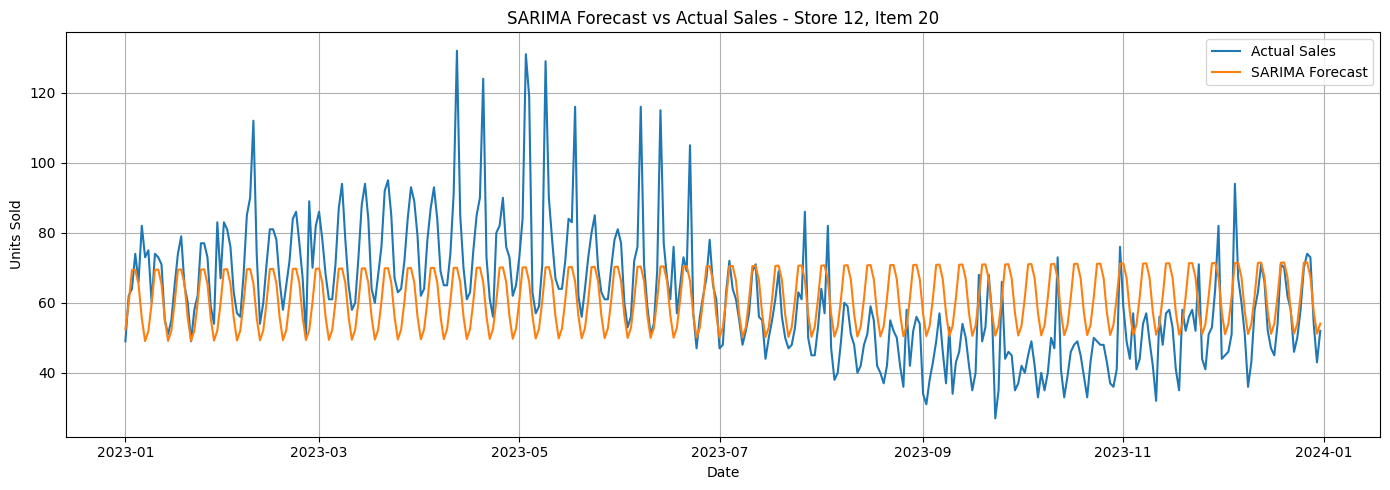

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


sarima_forecast = sarima_result.get_forecast(
    steps=len(test_sarima)
)

sarima_predictions = sarima_forecast.predicted_mean


sarima_predictions.index = test_sarima.index



sarima_predictions = sarima_predictions.clip(lower=0)


sarima_mae = mean_absolute_error(
    test_sarima, sarima_predictions
)

sarima_rmse = np.sqrt(
    mean_squared_error(test_sarima, sarima_predictions)
)

sarima_wape = (
    np.abs(test_sarima - sarima_predictions).sum()
    / np.abs(test_sarima).sum()
) * 100

print("SARIMA Model Performance")
print("------------------------")
print(f"MAE:  {sarima_mae:.2f}")
print(f"RMSE: {sarima_rmse:.2f}")
print(f"WAPE: {sarima_wape:.2f}%")


plt.figure(figsize=(14, 5))
plt.plot(test_sarima.index, test_sarima,
         label="Actual Sales")
plt.plot(sarima_predictions.index, sarima_predictions,
         label="SARIMA Forecast")
plt.title("SARIMA Forecast vs Actual Sales - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


xgb_sample = forecast_results[
    (forecast_results["store_id"] == "store_12") &
    (forecast_results["item_id"] == "item_20")
].copy()


xgb_sample = xgb_sample.sort_values("date")


xgb_mae = mean_absolute_error(
    xgb_sample["sales"],
    xgb_sample["predicted_sales"]
)

xgb_rmse = np.sqrt(mean_squared_error(
    xgb_sample["sales"],
    xgb_sample["predicted_sales"]
))

xgb_wape = (
    np.abs(
        xgb_sample["sales"] - xgb_sample["predicted_sales"]
    ).sum()
    / np.abs(xgb_sample["sales"]).sum()
) * 100


comparison = pd.DataFrame({
    "Model": ["XGBoost", "SARIMA"],
    "MAE": [xgb_mae, sarima_mae],
    "RMSE": [xgb_rmse, sarima_rmse],
    "WAPE (%)": [xgb_wape, sarima_wape]
})

print(comparison.round(2).to_string(index=False))

  Model   MAE  RMSE  WAPE (%)
XGBoost  2.81  3.41      5.52
 SARIMA 12.57 15.78     20.24


In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


improved_model = SARIMAX(
    train_sarima,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

improved_result = improved_model.fit(disp=False)


improved_predictions = improved_result.forecast(
    steps=len(test_sarima)
)

improved_predictions.index = test_sarima.index
improved_predictions = improved_predictions.clip(lower=0)


improved_mae = mean_absolute_error(
    test_sarima, improved_predictions
)

improved_rmse = np.sqrt(mean_squared_error(
    test_sarima, improved_predictions
))

improved_wape = (
    np.abs(test_sarima - improved_predictions).sum()
    / np.abs(test_sarima).sum()
) * 100

print("Improved SARIMA Results")
print("-----------------------")
print(f"MAE:  {improved_mae:.2f}")
print(f"RMSE: {improved_rmse:.2f}")
print(f"WAPE: {improved_wape:.2f}%")

Improved SARIMA Results
-----------------------
MAE:  42.70
RMSE: 52.62
WAPE: 68.75%


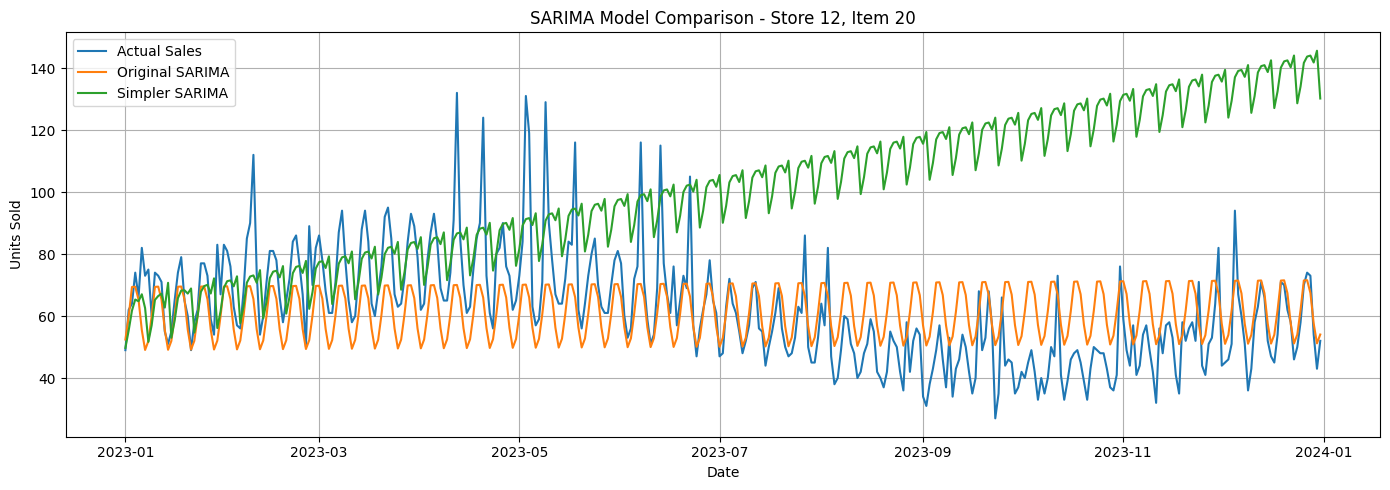

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    test_sarima.index,
    test_sarima,
    label="Actual Sales"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="Original SARIMA"
)

plt.plot(
    improved_predictions.index,
    improved_predictions,
    label="Simpler SARIMA"
)

plt.title("SARIMA Model Comparison - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

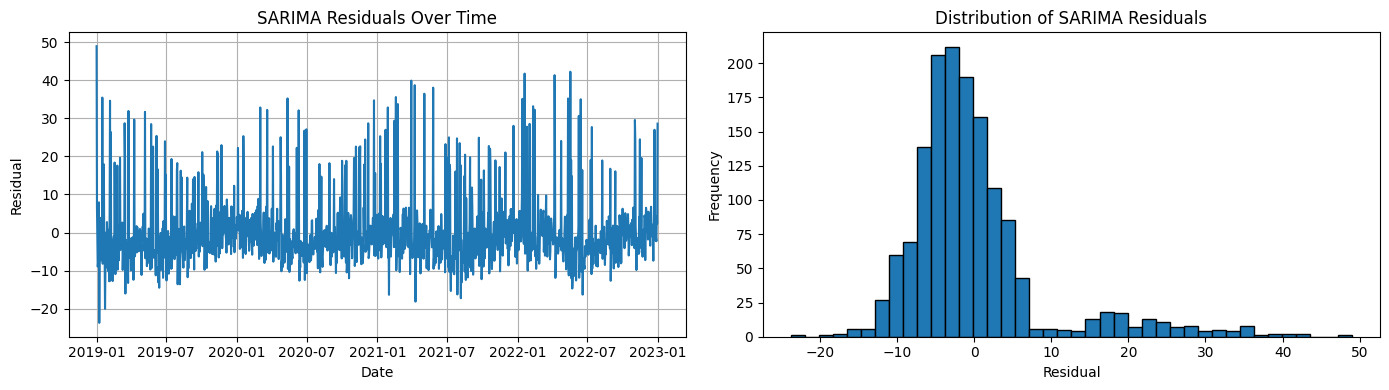

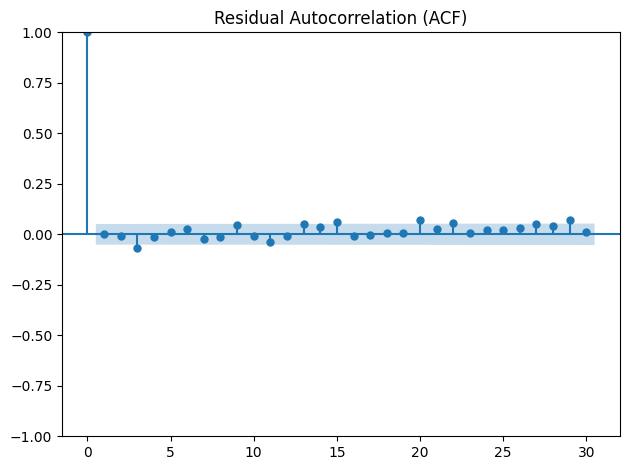

      lb_stat  lb_pvalue
7    8.451579   0.294461
14  20.002377   0.130066
21  34.662536   0.030738


In [29]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


residuals = sarima_result.resid.dropna()


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(residuals)
axes[0].set_title("SARIMA Residuals Over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residual")
axes[0].grid(True)

axes[1].hist(residuals, bins=40, edgecolor="black")
axes[1].set_title("Distribution of SARIMA Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


plot_acf(residuals, lags=30)
plt.title("Residual Autocorrelation (ACF)")
plt.tight_layout()
plt.show()


print(acorr_ljungbox(residuals, lags=[7, 14, 21], return_df=True))

In [31]:

print("Training data missing values:")
print(exog_train.isna().sum())

print("\nTesting data missing values:")
print(exog_test.isna().sum())

print("\nInfinite values in training data:")
print(np.isinf(exog_train.select_dtypes(include="number")).sum())

print("\nInfinite values in testing data:")
print(np.isinf(exog_test.select_dtypes(include="number")).sum())

Training data missing values:
price    1461
promo    1461
dtype: int64

Testing data missing values:
price    365
promo    365
dtype: int64

Infinite values in training data:
price    0
promo    0
dtype: int64

Infinite values in testing data:
price    0
promo    0
dtype: int64


In [32]:

exog_data = df[
    (df["store_id"] == "store_12") &
    (df["item_id"] == "item_20")
].copy()

exog_data["date"] = pd.to_datetime(exog_data["date"])
exog_data = exog_data.sort_values("date")
exog_data = exog_data.set_index("date")


exog_data = exog_data[["price", "promo"]].reindex(
    sales_series.index
)


exog_train = exog_data.loc[train_sarima.index].copy()
exog_test = exog_data.loc[test_sarima.index].copy()


print("Training missing values:")
print(exog_train.isna().sum())

print("\nTesting missing values:")
print(exog_test.isna().sum())

print("\nTraining sample:")
display(exog_train.head())

Training missing values:
price    0
promo    0
dtype: int64

Testing missing values:
price    0
promo    0
dtype: int64

Training sample:


,price,promo
date,,
2019-01-01,57.53,0
2019-01-02,57.53,0
2019-01-03,57.53,0
2019-01-04,57.53,0
2019-01-05,57.53,0


In [33]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create SARIMAX model
sarimax_model = SARIMAX(
    train_sarima,
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model
sarimax_result = sarimax_model.fit(disp=False)

# Forecast the test period
sarimax_predictions = sarimax_result.forecast(
    steps=len(test_sarima),
    exog=exog_test
)

# Keep predictions non-negative
sarimax_predictions = sarimax_predictions.clip(lower=0)

# Evaluate performance
sarimax_mae = mean_absolute_error(
    test_sarima, sarimax_predictions
)

sarimax_rmse = np.sqrt(
    mean_squared_error(test_sarima, sarimax_predictions)
)

sarimax_wape = (
    np.abs(test_sarima - sarimax_predictions).sum()
    / np.abs(test_sarima).sum()
) * 100

print("SARIMAX Model Performance")
print("-------------------------")
print(f"MAE:  {sarimax_mae:.2f}")
print(f"RMSE: {sarimax_rmse:.2f}")
print(f"WAPE: {sarimax_wape:.2f}%")

SARIMAX Model Performance
-------------------------
MAE:  38.52
RMSE: 49.04
WAPE: 62.01%


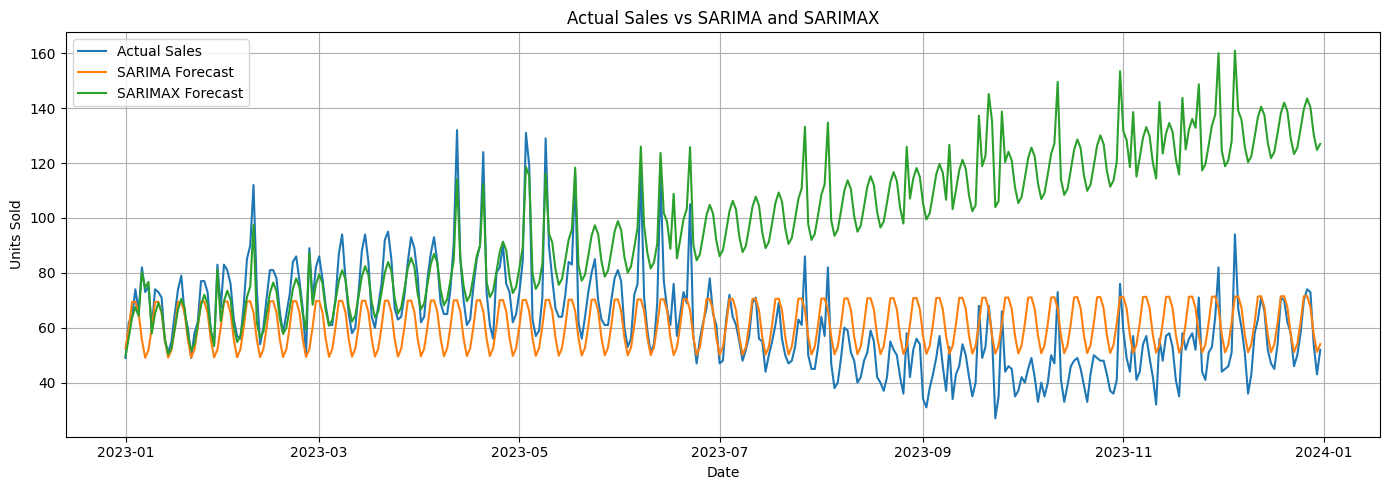

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    test_sarima.index,
    test_sarima,
    label="Actual Sales"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Forecast"
)

plt.plot(
    sarimax_predictions.index,
    sarimax_predictions,
    label="SARIMAX Forecast"
)

plt.title("Actual Sales vs SARIMA and SARIMAX")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.abs(actual - predicted).sum()
        / np.abs(actual).sum()
    ) * 100

    return {
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2)
    }


comparison = pd.DataFrame({
    "Original SARIMA": calculate_metrics(
        test_sarima, sarima_predictions
    ),
    "Simpler SARIMA": calculate_metrics(
        test_sarima, improved_predictions
    ),
    "SARIMAX": calculate_metrics(
        test_sarima, sarimax_predictions
    )
}).T

print("2023 Forecast Comparison: Store 12, Item 20")
display(comparison.sort_values("WAPE (%)"))

2023 Forecast Comparison: Store 12, Item 20


,MAE,RMSE,WAPE (%)
Original SARIMA,12.57,15.78,20.24
SARIMAX,38.52,49.04,62.01
Simpler SARIMA,42.70,52.62,68.75


In [36]:

final_comparison = comparison.reset_index()
final_comparison = final_comparison.rename(
    columns={"index": "Model"}
)


final_comparison.to_csv(
    "/content/retail_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
display(final_comparison)

Model comparison saved successfully!


,Model,MAE,RMSE,WAPE (%)
0,Original SARIMA,12.57,15.78,20.24
1,Simpler SARIMA,42.70,52.62,68.75
2,SARIMAX,38.52,49.04,62.01


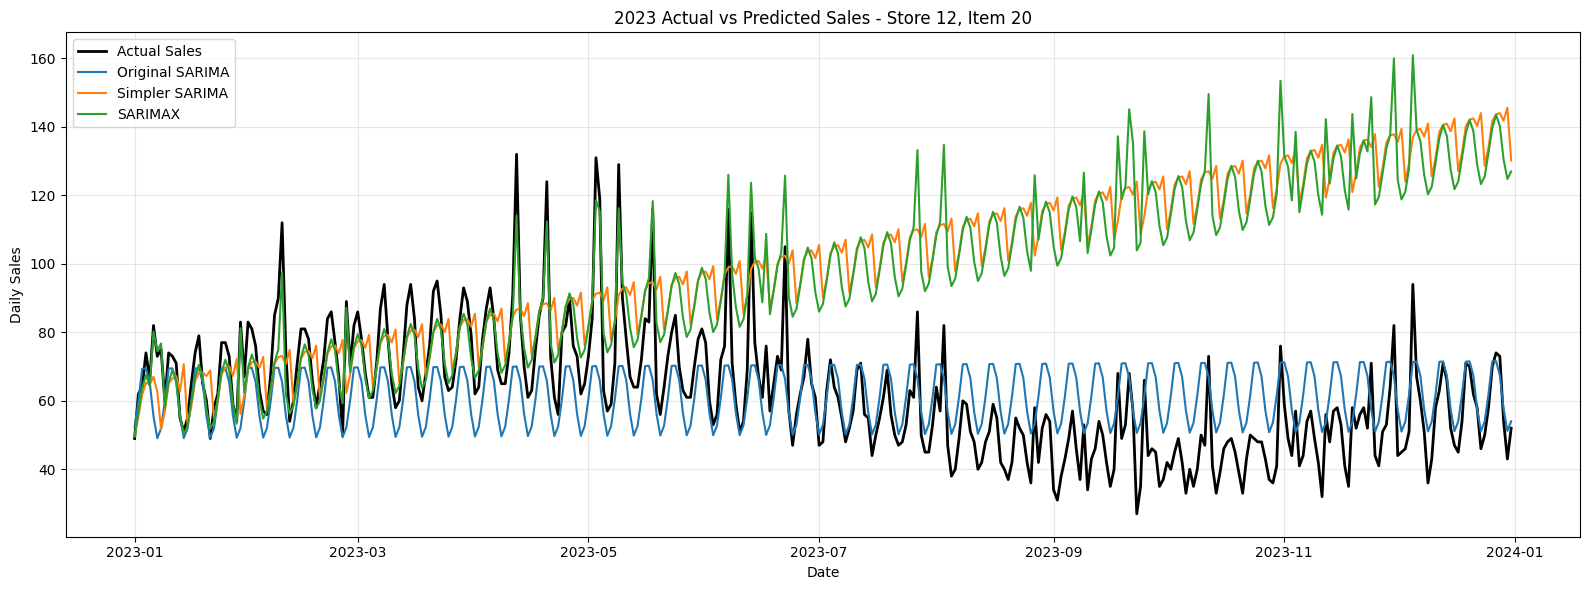

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    test_sarima.index,
    test_sarima,
    label="Actual Sales",
    color="black",
    linewidth=2
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="Original SARIMA",
    linewidth=1.5
)

plt.plot(
    improved_predictions.index,
    improved_predictions,
    label="Simpler SARIMA",
    linewidth=1.5
)

plt.plot(
    sarimax_predictions.index,
    sarimax_predictions,
    label="SARIMAX",
    linewidth=1.5
)

plt.title("2023 Actual vs Predicted Sales - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


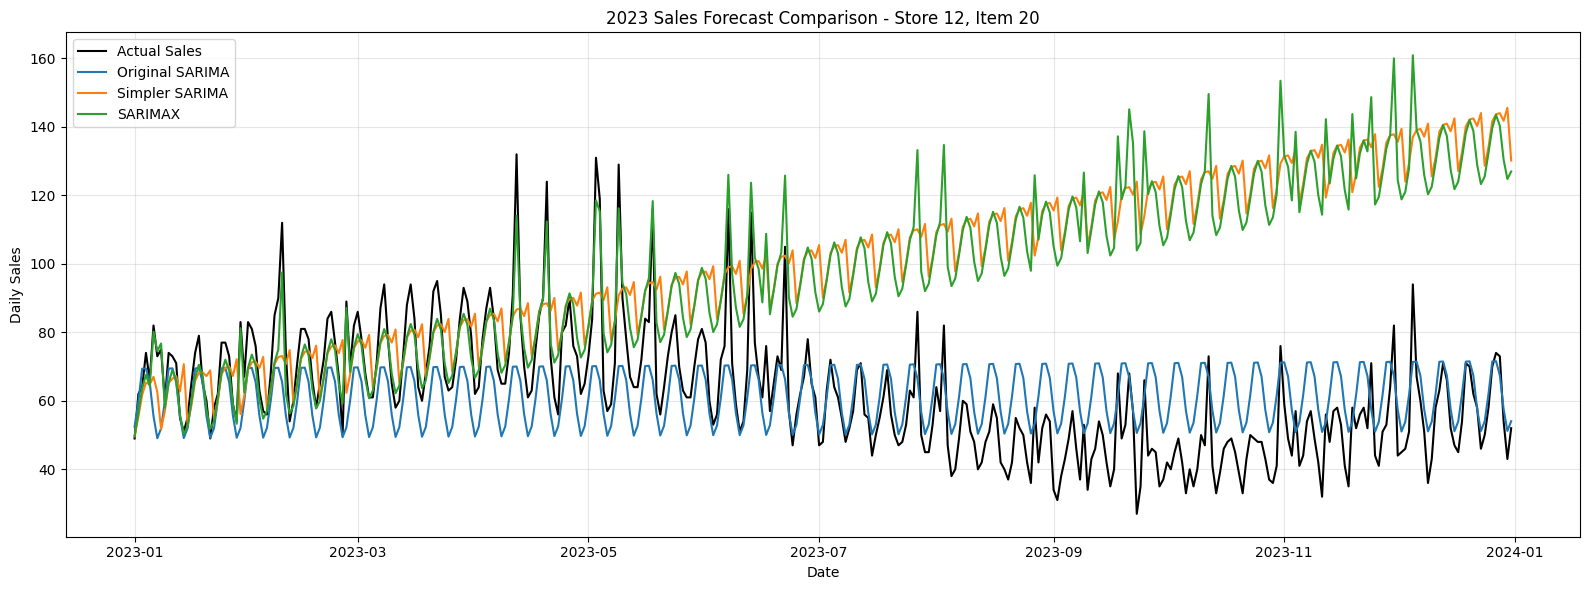

Graph saved successfully!


In [38]:

plt.figure(figsize=(16, 6))

plt.plot(test_sarima.index, test_sarima, label="Actual Sales", color="black")
plt.plot(sarima_predictions.index, sarima_predictions, label="Original SARIMA")
plt.plot(improved_predictions.index, improved_predictions, label="Simpler SARIMA")
plt.plot(sarimax_predictions.index, sarimax_predictions, label="SARIMAX")

plt.title("2023 Sales Forecast Comparison - Store 12, Item 20")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/sarima_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")


In [39]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd


xgb_sample = forecast_results[
    (forecast_results["store_id"] == "store_12") &
    (forecast_results["item_id"] == "item_20")
].copy()

xgb_sample["date"] = pd.to_datetime(xgb_sample["date"])
xgb_sample = xgb_sample.set_index("date").sort_index()


start_date = "2023-07-01"
end_date = "2023-12-31"

xgb_sample = xgb_sample.loc[start_date:end_date]
sarima_actual = test_sarima.loc[start_date:end_date]
sarima_pred = sarima_predictions.loc[start_date:end_date]


comparison_data = pd.DataFrame({
    "Actual_Sales": sarima_actual,
    "SARIMA_Prediction": sarima_pred,
    "XGBoost_Prediction": xgb_sample["predicted_sales"]
}).dropna()


results = []

for model_name, prediction_column in [
    ("SARIMA", "SARIMA_Prediction"),
    ("XGBoost", "XGBoost_Prediction")
]:
    actual = comparison_data["Actual_Sales"]
    predicted = comparison_data[prediction_column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.abs(actual - predicted).sum()
        / np.abs(actual).sum()
    ) * 100

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2)
    })

model_comparison = pd.DataFrame(results)
display(model_comparison)


,Model,MAE,RMSE,WAPE (%)
0,SARIMA,12.14,13.96,23.82
1,XGBoost,2.81,3.41,5.52


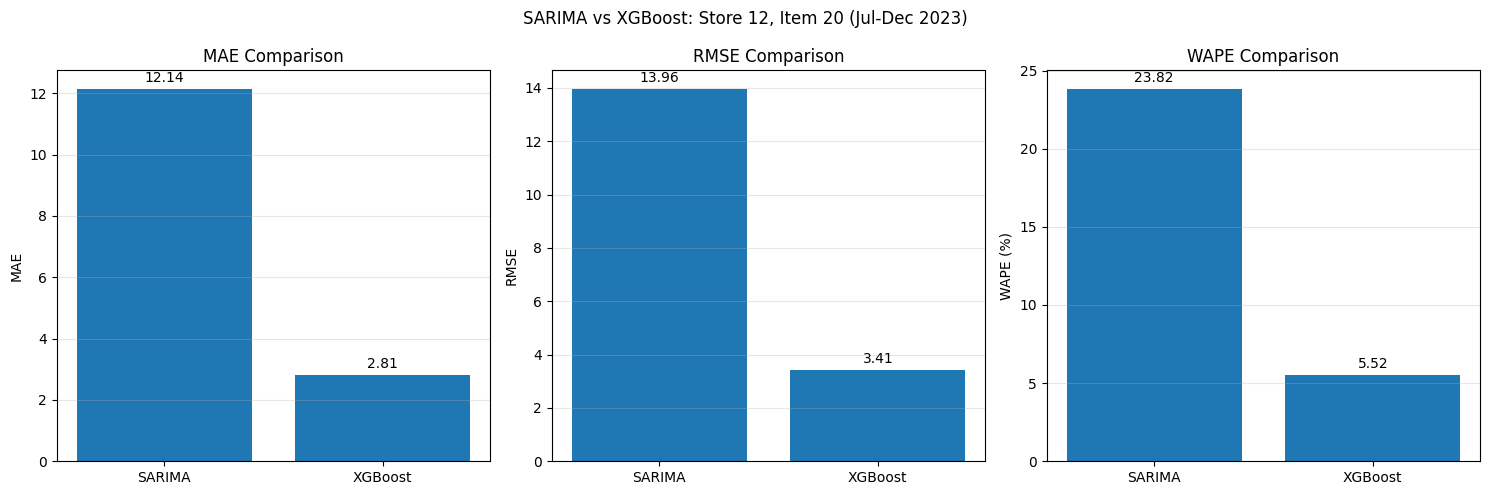

Model performance chart saved successfully!


In [40]:

import matplotlib.pyplot as plt
import numpy as np

models = ["SARIMA", "XGBoost"]
mae_values = [12.14, 2.81]
rmse_values = [13.96, 3.41]
wape_values = [23.82, 5.52]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ("MAE Comparison", mae_values, "MAE"),
    ("RMSE Comparison", rmse_values, "RMSE"),
    ("WAPE Comparison", wape_values, "WAPE (%)")
]

for ax, (title, values, ylabel) in zip(axes, metrics):
    bars = ax.bar(models, values)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "SARIMA vs XGBoost: Store 12, Item 20 (Jul-Dec 2023)"
)
plt.tight_layout()
plt.savefig(
    "/content/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Model performance chart saved successfully!")


In [41]:

import pandas as pd
import numpy as np


inventory_data = forecast_results.copy()
inventory_data["date"] = pd.to_datetime(inventory_data["date"])


inventory_summary = (
    inventory_data
    .groupby(["store_id", "item_id"])
    .agg(
        average_daily_demand=("predicted_sales", "mean"),
        total_forecast_demand=("predicted_sales", "sum")
    )
    .reset_index()
)


lead_time_days = 3
review_period_days = 7
safety_stock_percentage = 0.20


inventory_summary["safety_stock"] = np.ceil(
    inventory_summary["average_daily_demand"]
    * lead_time_days
    * safety_stock_percentage
)

inventory_summary["reorder_point"] = np.ceil(
    inventory_summary["average_daily_demand"] * lead_time_days
) + inventory_summary["safety_stock"]


inventory_summary["target_stock_7_days"] = np.ceil(
    inventory_summary["average_daily_demand"]
    * (lead_time_days + review_period_days)
) + inventory_summary["safety_stock"]


display(inventory_summary.head(10))



,store_id,item_id,average_daily_demand,total_forecast_demand,safety_stock,reorder_point,target_stock_7_days
0,store_1,item_1,40.013744,7362.528809,25.0,146.0,426.0
1,store_1,item_10,20.290892,3733.523926,13.0,74.0,216.0
2,store_1,item_11,21.894320,4028.554932,14.0,80.0,233.0
3,store_1,item_12,19.287739,3548.943848,12.0,70.0,205.0
4,store_1,item_13,36.313515,6681.686523,22.0,131.0,386.0
5,store_1,item_14,21.004860,3864.894287,13.0,77.0,224.0
6,store_1,item_15,18.899660,3477.537598,12.0,69.0,201.0
7,store_1,item_16,27.575323,5073.859375,17.0,100.0,293.0
8,store_1,item_17,15.087056,2776.018311,10.0,56.0,161.0
9,store_1,item_18,34.501320,6348.242676,21.0,125.0,367.0


In [42]:

inventory_summary.to_csv(
    "/content/inventory_recommendations.csv",
    index=False
)

print("Inventory recommendations saved successfully!")
print("Number of store-item combinations:", len(inventory_summary))


Inventory recommendations saved successfully!
Number of store-item combinations: 2500


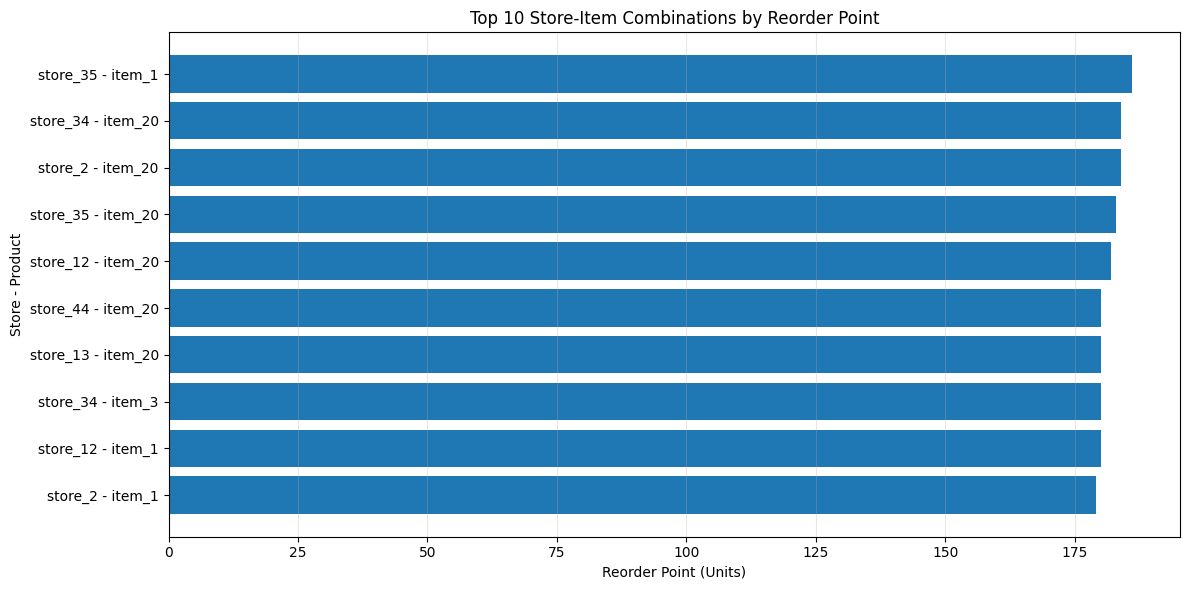

In [43]:

import matplotlib.pyplot as plt
import pandas as pd


top_inventory = inventory_summary.sort_values(
    "reorder_point", ascending=False
).head(10).copy()

top_inventory["product"] = (
    top_inventory["store_id"].astype(str)
    + " - "
    + top_inventory["item_id"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_inventory["product"],
    top_inventory["reorder_point"]
)

plt.xlabel("Reorder Point (Units)")
plt.ylabel("Store - Product")
plt.title("Top 10 Store-Item Combinations by Reorder Point")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/top_10_inventory_recommendations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [44]:

display(
    top_inventory[
        [
            "store_id",
            "item_id",
            "average_daily_demand",
            "safety_stock",
            "reorder_point",
            "target_stock_7_days"
        ]
    ].round(2)
)


,store_id,item_id,average_daily_demand,safety_stock,reorder_point,target_stock_7_days
1400,store_35,item_1,51.599998,31.0,186.0,548.0
1362,store_34,item_20,50.730000,31.0,184.0,539.0
562,store_2,item_20,51.000000,31.0,184.0,541.0
1412,store_35,item_20,50.570000,31.0,183.0,537.0
162,store_12,item_20,50.220001,31.0,182.0,534.0
1912,store_44,item_20,49.880001,30.0,180.0,529.0
212,store_13,item_20,49.820000,30.0,180.0,529.0
1372,store_34,item_3,49.930000,30.0,180.0,530.0
150,store_12,item_1,49.759998,30.0,180.0,528.0
550,store_2,item_1,49.360001,30.0,179.0,524.0


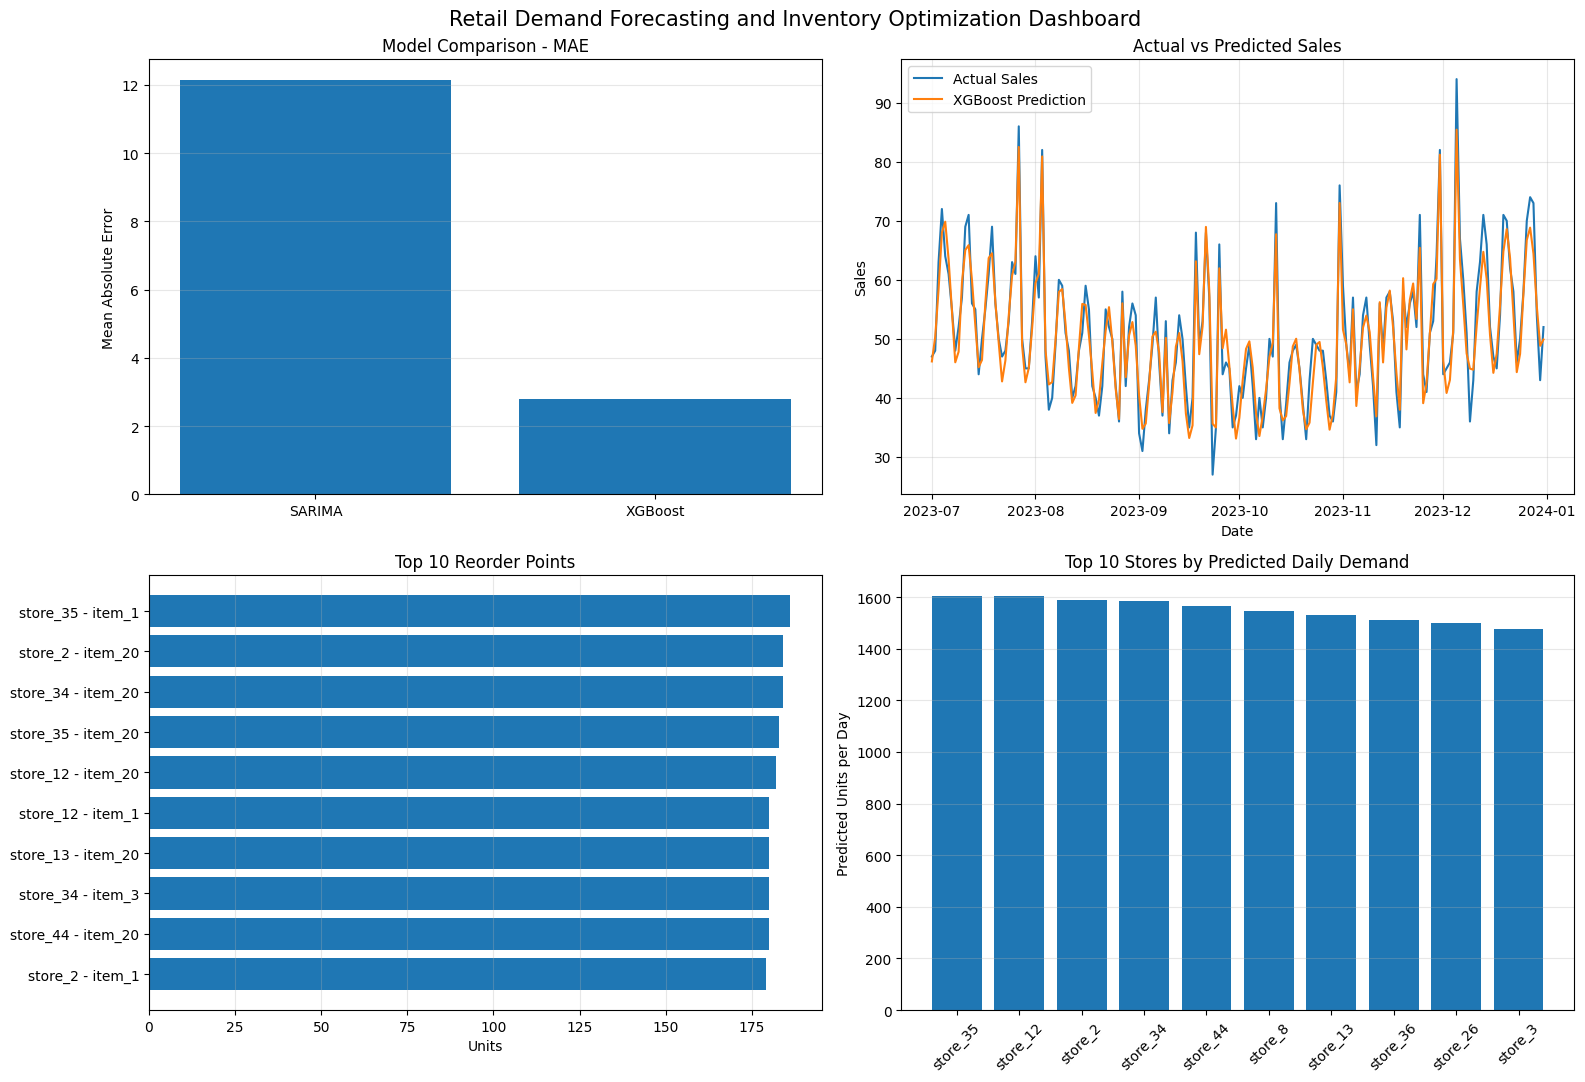

Dashboard created and saved successfully!


In [45]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display


fig, axes = plt.subplots(2, 2, figsize=(16, 11))


models = ["SARIMA", "XGBoost"]
mae_values = [12.14, 2.81]

axes[0, 0].bar(models, mae_values)
axes[0, 0].set_title("Model Comparison - MAE")
axes[0, 0].set_ylabel("Mean Absolute Error")
axes[0, 0].grid(axis="y", alpha=0.3)


sample = forecast_results[
    (forecast_results["store_id"] == "store_12") &
    (forecast_results["item_id"] == "item_20")
].copy()

sample["date"] = pd.to_datetime(sample["date"])
sample = sample.sort_values("date")

axes[0, 1].plot(
    sample["date"], sample["sales"],
    label="Actual Sales"
)
axes[0, 1].plot(
    sample["date"], sample["predicted_sales"],
    label="XGBoost Prediction"
)
axes[0, 1].set_title("Actual vs Predicted Sales")
axes[0, 1].set_xlabel("Date")
axes[0, 1].set_ylabel("Sales")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


top10 = inventory_summary.nlargest(10, "reorder_point").copy()
top10["product"] = top10["store_id"] + " - " + top10["item_id"]

axes[1, 0].barh(top10["product"], top10["reorder_point"])
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("Top 10 Reorder Points")
axes[1, 0].set_xlabel("Units")
axes[1, 0].grid(axis="x", alpha=0.3)


store_demand = (
    inventory_summary.groupby("store_id")["average_daily_demand"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

axes[1, 1].bar(store_demand.index, store_demand.values)
axes[1, 1].set_title("Top 10 Stores by Predicted Daily Demand")
axes[1, 1].set_ylabel("Predicted Units per Day")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "Retail Demand Forecasting and Inventory Optimization Dashboard",
    fontsize=15
)
plt.tight_layout()

plt.savefig(
    "/content/retail_forecasting_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Dashboard created and saved successfully!")


In [46]:

print("Total store-item combinations:", len(inventory_summary))
print(
    "Average daily demand across store-item combinations:",
    round(inventory_summary["average_daily_demand"].mean(), 2)
)
print(
    "Highest reorder point:",
    int(inventory_summary["reorder_point"].max()),
    "units"
)

display(inventory_summary.head(10))


Total store-item combinations: 2500
Average daily demand across store-item combinations: 26.46
Highest reorder point: 186 units


,store_id,item_id,average_daily_demand,total_forecast_demand,safety_stock,reorder_point,target_stock_7_days
0,store_1,item_1,40.013744,7362.528809,25.0,146.0,426.0
1,store_1,item_10,20.290892,3733.523926,13.0,74.0,216.0
2,store_1,item_11,21.894320,4028.554932,14.0,80.0,233.0
3,store_1,item_12,19.287739,3548.943848,12.0,70.0,205.0
4,store_1,item_13,36.313515,6681.686523,22.0,131.0,386.0
5,store_1,item_14,21.004860,3864.894287,13.0,77.0,224.0
6,store_1,item_15,18.899660,3477.537598,12.0,69.0,201.0
7,store_1,item_16,27.575323,5073.859375,17.0,100.0,293.0
8,store_1,item_17,15.087056,2776.018311,10.0,56.0,161.0
9,store_1,item_18,34.501320,6348.242676,21.0,125.0,367.0


In [47]:

import os
import zipfile

output_folder = "/content/retail_project_outputs"
os.makedirs(output_folder, exist_ok=True)

files_to_export = [
    "/content/xgboost_test_predictions.csv",
    "/content/inventory_recommendations.csv",
    "/content/retail_model_comparison.csv",
    "/content/sarima_forecast_comparison.png",
    "/content/model_performance_comparison.png",
    "/content/top_10_inventory_recommendations.png",
    "/content/retail_forecasting_dashboard.png"
]

copied_files = []

for file_path in files_to_export:
    if os.path.exists(file_path):
        destination = os.path.join(
            output_folder, os.path.basename(file_path)
        )
        with open(file_path, "rb") as source:
            with open(destination, "wb") as target:
                target.write(source.read())
        copied_files.append(destination)
    else:
        print("Not found (may not have been created):", file_path)

zip_path = "/content/retail_forecasting_project_outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in copied_files:
        zipf.write(file_path, arcname=os.path.basename(file_path))

print("\nFiles included:", len(copied_files))
print("ZIP file created:", zip_path)



Files included: 7
ZIP file created: /content/retail_forecasting_project_outputs.zip


In [48]:

from google.colab import files

files.download("/content/retail_forecasting_project_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

readme_content = """
# Advanced Retail Demand Forecasting and Inventory Optimization

## 1. Project Overview
This project uses time-series analysis and machine learning
to forecast retail product demand and support inventory planning.

## 2. Problem Statement
Retail businesses need accurate demand forecasts to reduce
stockouts, avoid excess inventory, and improve stock planning.

## 3. Dataset
- 4,565,000 records
- 50 stores
- 50 products
- Daily sales data from 2019 to 2023
- Features include date, store_id, item_id, sales,
  price, promo, weekday, and month

## 4. Technologies Used
- Python
- Pandas and NumPy
- Matplotlib
- Statsmodels
- Scikit-learn
- XGBoost
- Google Colab

## 5. Models
- SARIMA
- SARIMAX
- XGBoost Regressor

## 6. Model Evaluation
Store 12, Item 20, July-December 2023:

| Model | MAE | RMSE | WAPE |
|---|---:|---:|---:|
| SARIMA | 12.14 | 13.96 | 23.82% |
| XGBoost | 2.81 | 3.41 | 5.52% |

These results use different forecasting strategies:
XGBoost uses observed lagged sales during the test period,
while SARIMA produces a multi-step forecast. Therefore,
the comparison is preliminary and not fully like-for-like.

## 7. Inventory Optimization
The project calculates:
- Average predicted daily demand
- Safety stock
- Reorder point
- Target stock level

The current inventory calculations use assumed supplier
lead time and safety-stock percentage. Real inventory data
is needed for operational recommendations.

## 8. Outputs
- XGBoost test predictions
- SARIMA model comparison
- Inventory recommendations
- Forecasting dashboard
- Model performance charts

## 9. Future Improvements
- Perform a fair comparison using the same forecast horizon
- Tune model parameters
- Test additional forecasting models
- Use real supplier lead times and current stock levels
- Build an interactive Power BI dashboard

## 10. Conclusion
The project demonstrates how time-series forecasting and
machine learning can support retail demand prediction and
inventory planning.
"""

readme_path = "/content/README.md"

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")


README.md created successfully!


In [50]:

from google.colab import files
files.download("/content/README.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>